# IT9002 Lab 5.1: Tagging Words and Evaluating Named Entities

**Unit 05: Sequence Labeling and Information Extraction**

**IT9002 Natural Language Processing**

## Objectives

By the end of this lab, you should be able to:

- Use spaCy to assign part-of-speech tags and identify named entities in a text.
- Interpret the Doc, Token, and Span objects produced by processing a sentence.
- Identify named entities in a sentence using its BIO tags.
- Evaluate a named entity recognizer at the entity level and explain why token accuracy can overstate its performance.
- Use gensim to train a topic model and evaluate its topics against the known article categories.

## Data

- **CoNLL-2003** (Tjong Kim Sang and De Meulder, 2003), 1,000 sentences of Reuters news from the English test split, with their part-of-speech and named entity tags, https://huggingface.co/datasets/eriktks/conll2003, annotations free for research use, text under the Reuters research license.

- **BBC News** (Greene and Cunningham, 2006), 2,225 articles of the BBC News website from 2004 and 2005 in 5 categories, http://mlg.ucd.ie/datasets/bbc.html, provided by the authors for non-commercial and research use, article text copyright BBC.

- The course file `conll2003_sample.csv` (on Moodle).

- The course file `bbc_news.csv` (on Moodle).

The files `conll2003_sample.csv` and `bbc_news.csv` can be downloaded from Moodle. Download them to your computer, then run the cell below. If the files are already available in the runtime, the cell loads them directly; otherwise, it opens a file-upload dialog.

In [1]:
from pathlib import Path
import pandas as pd

def course_file(name):
    path = next((p for p in (Path(name), Path("data") / name) if p.exists()), None)
    if path is None:
        from google.colab import files
        files.upload()
        path = Path(name)
    return path

conll = pd.read_csv(course_file("conll2003_sample.csv"), index_col="sentence_id")
bbc = pd.read_csv(course_file("bbc_news.csv"))
print(conll.shape, bbc.shape)
conll.head()

(1000, 3) (2225, 3)


,tokens,pos_tags,ner_tags
sentence_id,,,
8,Despite winning the Asian Games title two year...,"IN VBG DT JJ NNPS NN CD NNS RB , NNP VBP IN DT...",O O O B-MISC I-MISC O O O O O B-LOC O O O O O O O
20,Hosts UAE play Kuwait and South Korea take on ...,NNPS NNP NN NNP CC NNP NNP VBP IN NNP IN NNP I...,O B-LOC O B-LOC O B-LOC I-LOC O O B-LOC O O O ...
29,Coste said he had approached the player two mo...,NNP VBD PRP VBD VBN DT NN CD NNS RB RB DT NN .,B-PER O O O O O O O O O O O O O
33,"Squad : Javier Pertile , Paolo Vaccari , Marce...","VB : NNP NNP , NNP NNP , NNP NNP , NNP NNP , N...",O O B-PER I-PER O B-PER I-PER O B-PER I-PER O ...
34,SOCCER - LATE GOALS GIVE JAPAN WIN OVER SYRIA .,NN : JJ NNS VBP NNP NNP IN NNP .,O O O O O B-LOC O O B-LOC O


## Setup

**spaCy** is preinstalled in Google Colab, and **gensim**, a library used for topic modeling, has not been installed. The following cell installs each library if it is not already available.

In [2]:
import importlib.util, subprocess, sys

for package in ("spacy", "gensim"):
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

Imports the libraries and tools required for the lab and displays the installed versions of **pandas**, spaCy, `en_core_web_sm`, and gensim.

`en_core_web_sm` is spaCy's small English pipeline, which is downloaded if it is not already installed.

The English stop-word list of **NLTK** is downloaded for the topic model.

In [3]:
import collections
import gensim
import matplotlib.pyplot as plt
import numpy as np
import nltk
import spacy
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel
from nltk.corpus import stopwords
from spacy import displacy
from spacy.tokens import Doc

try:
    nlp_spacy = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp_spacy = spacy.load("en_core_web_sm")

nltk.download("stopwords", quiet=True)
print("pandas", pd.__version__, "| spaCy", spacy.__version__, "| en_core_web_sm", nlp_spacy.meta["version"],
      "| gensim", gensim.__version__)

pandas 3.0.2 | spaCy 3.8.16 | en_core_web_sm 3.8.0 | gensim 4.4.0


## 1. Components of the spaCy Pipeline

`pipe_names` contains the names of the components of the `en_core_web_sm` pipeline in the order in which they run after the tokenizer.

In [4]:
print(nlp_spacy.pipe_names)

['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## 2. Part-of-Speech Tags in Context

spaCy assigns each token a broad part-of-speech category in `pos_` and a more detailed Penn Treebank tag in `tag_`.

`spacy.explain()` returns the meaning of a tag.

The part-of-speech tags assigned to `light` are displayed for 3 sentences:

In [5]:
sentences = ["Light the candles before dinner.", "She carried a light bag.", "The light was too bright."]
rows = []
for sentence in sentences:
    for token in nlp_spacy(sentence):
        if token.lower_ == "light":
            rows.append((sentence, token.pos_, token.tag_, spacy.explain(token.tag_)))
pd.DataFrame(rows, columns=["sentence", "pos_", "tag_", "meaning of tag_"])

,sentence,pos_,tag_,meaning of tag_
0,Light the candles before dinner.,VERB,VB,"verb, base form"
1,She carried a light bag.,ADJ,JJ,"adjective (English), other noun-modifier (Chin..."
2,The light was too bright.,NOUN,NN,"noun, singular or mass"


## 3. Documents, Tokens, and Spans

Passing a text to `nlp_spacy()` returns a **Doc**. Indexing the Doc returns a **Token**, and slicing it returns a **Span**.

The Doc of the sentence `Layla Hassan opened a bakery in Manama on Monday.` is displayed with the Token `doc[6]` and the Span `doc[0:2]`, which contains the tokens at positions 0 and 1:

In [6]:
doc = nlp_spacy("Layla Hassan opened a bakery in Manama on Monday.")
print(type(doc).__name__, "|", type(doc[6]).__name__, doc[6], "|", type(doc[0:2]).__name__, doc[0:2])

Doc | Token Manama | Span Layla Hassan


Each named entity is a labeled Span, and `doc.ents` contains all the named entities of the Doc.

Each entity is displayed with its text, its type, the position of its first token, and the position after its last token:

In [7]:
for ent in doc.ents:
    print(ent.text, ent.label_, ent.start, ent.end)

Layla Hassan PERSON 0 2
Manama GPE 6 7
Monday DATE 8 9


The attributes of each Token are displayed in a table:

- `ent_iob_` contains the BIO tag of the token, without its entity type.

- `ent_type_` contains the entity type of the token, which will be empty for a token outside any entity.

In [8]:
pd.DataFrame([(t.i, t.text, t.pos_, t.ent_iob_, t.ent_type_) for t in doc],
             columns=["position", "text", "pos_", "ent_iob_", "ent_type_"])

,position,text,pos_,ent_iob_,ent_type_
0,0,Layla,PROPN,B,PERSON
1,1,Hassan,PROPN,I,PERSON
2,2,opened,VERB,O,
3,3,a,DET,O,
4,4,bakery,NOUN,O,
5,5,in,ADP,O,
6,6,Manama,PROPN,B,GPE
7,7,on,ADP,O,
8,8,Monday,PROPN,B,DATE
9,9,.,PUNCT,O,


## 4. Part-of-Speech Tags and Named Entities in 200 News Sentences

The sentences of the file are already tokenized, and each token is assigned its gold tag.

spaCy's tokenizer may split a sentence differently, which would misalign its predicted tags with the gold tags.

To keep the original tokens, `run_spacy()` constructs a Doc from the tokens of each sentence with `Doc()` and runs the pipeline on it.

The first 200 rows of the file are processed to assign part-of-speech tags and named entities:

In [9]:
def run_spacy(tokens):
    return nlp_spacy(Doc(nlp_spacy.vocab, words=tokens.split(" ")))

docs = [run_spacy(tokens) for tokens in conll["tokens"].head(200)]
print(len(docs), "sentences |", sum(len(doc) for doc in docs), "tokens")

200 sentences | 2707 tokens


The frequencies of the 8 most common part-of-speech categories in the 200 sentences are calculated:

In [10]:
pos_counts = collections.Counter(token.pos_ for doc in docs for token in doc)
pd.DataFrame([(pos, n, spacy.explain(pos)) for pos, n in pos_counts.most_common(8)],
             columns=["pos_", "tokens", "meaning"])

,pos_,tokens,meaning
0,PROPN,780,proper noun
1,NUM,541,numeral
2,PUNCT,480,punctuation
3,NOUN,273,noun
4,ADP,177,adposition
5,VERB,135,verb
6,DET,77,determiner
7,ADJ,76,adjective


Proper nouns and numbers are the most frequent categories, because the news sentences contain many names and sports results.

The named entities that spaCy identifies in the 200 sentences are counted by type:

In [11]:
ent_counts = collections.Counter(ent.label_ for doc in docs for ent in doc.ents)
print(sum(ent_counts.values()), "entities")
pd.DataFrame([(label, n, spacy.explain(label)) for label, n in ent_counts.most_common()],
             columns=["label_", "entities", "meaning"])

637 entities


,label_,entities,meaning
0,PERSON,159,"People, including fictional"
1,CARDINAL,137,Numerals that do not fall under another type
2,DATE,117,Absolute or relative dates or periods
3,GPE,96,"Countries, cities, states"
4,ORG,72,"Companies, agencies, institutions, etc."
5,NORP,15,Nationalities or religious or political groups
6,ORDINAL,13,"""first"", ""second"", etc."
7,EVENT,9,"Named hurricanes, battles, wars, sports events..."
8,MONEY,4,"Monetary values, including unit"
9,FAC,4,"Buildings, airports, highways, bridges, etc."


## 5. Visualizing Named Entities with displaCy

`conll.loc[144]` returns the row with the `sentence_id` 144.

Sentence `144` is processed with `run_spacy()`, and its named entities are displayed with `displacy.render()`:

In [12]:
doc_144 = run_spacy(conll.loc[144, "tokens"])
displacy.render(doc_144, style="ent", jupyter=True)

## 6. Identifying Named Entities from BIO Tags

`bio_spans()` identifies the named entities in a sequence of BIO tags and returns each one as `(start, end, type)`, where `end` is the position after the last token of the entity:

- A `B-` tag starts a new entity. An `I-` tag also starts a new entity when no entity of the same type is open.

- An `I-` tag of the same type extends the open entity, and any other tag closes it.

- An `O` tag is appended after the last tag, so that an entity that ends at the last token is also closed.

In [13]:
def bio_spans(tags):
    spans, start, kind = [], None, None
    for i, tag in enumerate(list(tags) + ["O"]):
        if start is not None and not (tag.startswith("I-") and tag[2:] == kind):
            spans.append((start, i, kind))
            start = None
        if tag.startswith("B-") or (tag.startswith("I-") and start is None):
            start, kind = i, tag[2:]
    return spans

`bio_spans()` is applied to the gold tags of the sentence `Sara joined Gulf Air as a pilot in 2019`:

In [14]:
words = ["Sara", "joined", "Gulf", "Air", "as", "a", "pilot", "in", "2019"]
gold = ["B-PER", "O", "B-ORG", "I-ORG", "O", "O", "O", "O", "O"]
for start, end, kind in bio_spans(gold):
    print(" ".join(words[start:end]), kind, start, end)

Sara PER 0 1
Gulf Air ORG 2 4


The gold entities of the 1,000 sentences are counted by type, along with the number of entities that span more than one token:

In [15]:
gold_tags = [tags.split(" ") for tags in conll["ner_tags"]]
gold_spans = [span for tags in gold_tags for span in bio_spans(tags)]
print(len(gold_spans), "gold entities")
print(collections.Counter(kind for _, _, kind in gold_spans).most_common())
print("more than one token:", sum(end - start > 1 for start, end, _ in gold_spans))

1887 gold entities
[('PER', 639), ('ORG', 536), ('LOC', 484), ('MISC', 228)]
more than one token: 758


## 7. An Entity-Level Scorer

In a prediction for the sentence about Sara, `Air` is incorrectly tagged `O`.

The gold and predicted tags are displayed in one table:

In [16]:
predicted = ["B-PER", "O", "B-ORG", "O", "O", "O", "O", "O", "O"]
pd.DataFrame([gold, predicted], index=["gold tag", "predicted tag"], columns=words)

,Sara,joined,Gulf,Air,as,a,pilot,in,2019
gold tag,B-PER,O,B-ORG,I-ORG,O,O,O,O,O
predicted tag,B-PER,O,B-ORG,O,O,O,O,O,O


`evaluate(gold_seqs, pred_seqs)` calculates token accuracy and entity-level precision, recall, and F1. It returns the counts and the scores, rounded to three decimal places:

- `gold_seqs`: a list of gold tag sequences, one for each sentence, for example `[gold]`.

- `pred_seqs`: a list of predicted tag sequences for the same sentences, for example `[predicted]`.

Each entity is stored as `(sentence, start, end, type)`. A predicted entity is correct only when its sentence, start, end, and type all match a gold entity.

Precision is undefined when no entity is predicted, and `evaluate()` returns 0 for it.

In [17]:
def evaluate(gold_seqs, pred_seqs):
    correct_tags = sum(g == p for gs, ps in zip(gold_seqs, pred_seqs) for g, p in zip(gs, ps))
    tokens = sum(len(gs) for gs in gold_seqs)
    gold_set = {(k, *span) for k, gs in enumerate(gold_seqs) for span in bio_spans(gs)}
    pred_set = {(k, *span) for k, ps in enumerate(pred_seqs) for span in bio_spans(ps)}
    correct = len(gold_set & pred_set)
    precision = correct / len(pred_set) if pred_set else 0.0
    recall = correct / len(gold_set) if gold_set else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"correct tags": correct_tags, "tokens": tokens, "correct entities": correct,
            "predicted entities": len(pred_set), "gold entities": len(gold_set),
            "token accuracy": round(correct_tags / tokens, 3), "precision": round(precision, 3),
            "recall": round(recall, 3), "F1": round(f1, 3)}

The predicted tags of the sentence about Sara are scored against its gold tags with `evaluate()`:

In [18]:
pd.Series(evaluate([gold], [predicted]), dtype=object)

correct tags              8
tokens                    9
correct entities          1
predicted entities        2
gold entities             2
token accuracy        0.889
precision               0.5
recall                  0.5
F1                      0.5
dtype: object

$$\text{token accuracy} = \frac{8}{9} = 0.889 \qquad\qquad \text{precision} = \frac{1}{2} = 0.500 \qquad\qquad \text{recall} = \frac{1}{2} = 0.500$$

$$\text{F1} = \frac{2 \times 0.5 \times 0.5}{0.5 + 0.5} = 0.500$$

## 8. Evaluating spaCy on 1,000 News Sentences

The proportion of gold tags that are `O` is calculated over the 1,000 sentences:

In [19]:
all_tags = [tag for tags in gold_tags for tag in tags]
print(len(all_tags), "tokens |", all_tags.count("O"), "tagged O |", f"{all_tags.count('O') / len(all_tags):.1%}")

16398 tokens | 13603 tagged O | 83.0%


A labeling that tags every token `O` therefore already achieves a token accuracy of **0.830**.

`CONLL_TYPE` maps 11 of spaCy's 18 entity types to the four CoNLL-2003 types, for example `PERSON` to `PER` and `GPE` to `LOC`.

The other 7 types, such as dates, money, and numbers, have no CoNLL-2003 type, and their tokens are tagged `O`.

`to_bio()` converts the entities of a Doc into a sequence of BIO tags in the CoNLL-2003 types.

In [20]:
CONLL_TYPE = {"PERSON": "PER", "ORG": "ORG", "GPE": "LOC", "LOC": "LOC", "FAC": "LOC",
              "NORP": "MISC", "EVENT": "MISC", "WORK_OF_ART": "MISC", "LAW": "MISC", "LANGUAGE": "MISC", "PRODUCT": "MISC"}

def to_bio(doc):
    tags = ["O"] * len(doc)
    for ent in doc.ents:
        if ent.label_ in CONLL_TYPE:
            tags[ent.start] = "B-" + CONLL_TYPE[ent.label_]
            for i in range(ent.start + 1, ent.end):
                tags[i] = "I-" + CONLL_TYPE[ent.label_]
    return tags

The gold and predicted entities of sentence `144` are displayed in the CoNLL-2003 types, followed by the scores of the sentence:

In [21]:
words_144 = conll.loc[144, "tokens"].split(" ")
gold_144, pred_144 = conll.loc[144, "ner_tags"].split(" "), to_bio(doc_144)
for name, tags in (("gold", gold_144), ("predicted", pred_144)):
    print(f"{name:>9}:", [(" ".join(words_144[start:end]), kind) for start, end, kind in bio_spans(tags)])
evaluate([gold_144], [pred_144])

     gold: [('Dutch', 'MISC'), ('Reggie Blinker', 'PER'), ('FIFA', 'ORG'), ('Sheffield Wednesday', 'ORG'), ('Liverpool', 'ORG')]
predicted: [('Dutch', 'MISC'), ('Reggie Blinker', 'PER'), ('FIFA', 'ORG'), ('Sheffield', 'LOC'), ('Liverpool', 'LOC')]


{'correct tags': 24,
 'tokens': 27,
 'correct entities': 3,
 'predicted entities': 5,
 'gold entities': 5,
 'token accuracy': 0.889,
 'precision': 0.6,
 'recall': 0.6,
 'F1': 0.6}

The predicted entity `Sheffield` differs from the gold entity `Sheffield Wednesday` in its boundaries and its type, and `Liverpool` differs only in its type.

spaCy tags all 1,000 sentences, and the scores are calculated for the labeling that tags every token `O` and for spaCy's tags:

In [22]:
spacy_tags = [to_bio(run_spacy(tokens)) for tokens in conll["tokens"]]
all_o = [["O"] * len(tags) for tags in gold_tags]
comparison = pd.DataFrame([evaluate(gold_tags, all_o), evaluate(gold_tags, spacy_tags)],
                          index=["Every token tagged O", "spaCy small English pipeline"])
comparison

,correct tags,tokens,correct entities,predicted entities,gold entities,token accuracy,precision,recall,F1
Every token tagged O,13603,16398,0,0,1887,0.830,0.000,0.000,0.000
spaCy small English pipeline,14986,16398,1058,1589,1887,0.914,0.666,0.561,0.609


The scores of the two labelings are compared in a grouped bar chart:

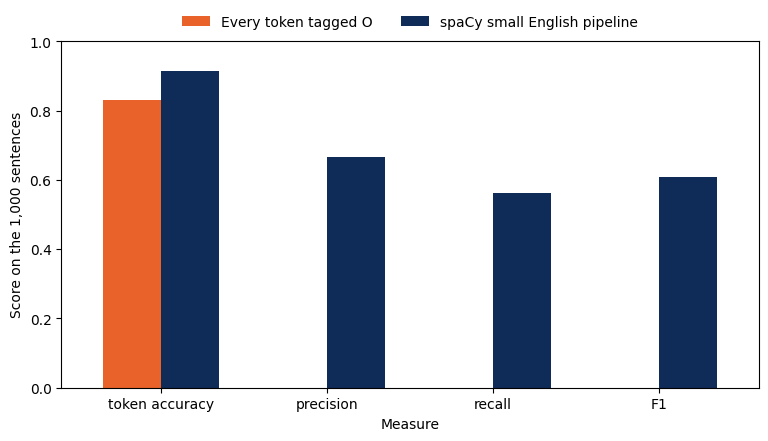

In [23]:
measures = ["token accuracy", "precision", "recall", "F1"]
ax = comparison[measures].T.plot.bar(figsize=(9, 4.5), width=0.7, color=["#E8622A", "#0F2B58"], rot=0)
ax.set_xlabel("Measure")
ax.set_ylabel("Score on the 1,000 sentences")
ax.set_ylim(0, 1)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
plt.show()

spaCy raises the token accuracy by only 0.084 over the labeling that tags every token `O`, to about **0.914**. It raises the entity-level F1 from 0 to about **0.609**.

## 9. Preparing News Articles for Topic Modeling

The 2,225 articles of `bbc` belong to 5 categories. The categories are not given to the topic model, and they are used afterwards to evaluate the topics it finds.

`lemmas()` converts each processed article into a list of lowercase lemmas in these steps:

- Only alphabetic tokens are kept, so that numbers and punctuation do not enter the topic model.

- Each word is replaced by its lemma, so that `films` and `film` are counted as one word.

- A word is removed when the word or its lemma is in NLTK's list of English stop words, since stop words occur in every article whatever its theme.

`nlp_spacy.pipe()` processes the articles in batches of 64, with the parser and the entity recognizer switched off, since lemmatization needs neither.

The total number of lemmas is displayed, with the title and the first 10 lemmas of article `253`:

In [24]:
STOP = set(stopwords.words("english"))

def lemmas(doc):
    return [t.lemma_.lower() for t in doc if t.is_alpha and t.lower_ not in STOP and t.lemma_.lower() not in STOP]

articles = [lemmas(doc) for doc in nlp_spacy.pipe(bbc["text"], batch_size=64, disable=["parser", "ner"])]
print(sum(len(article) for article in articles), "lemmas")
print(bbc.loc[253, "title"], "|", articles[253][:10])

472591 lemmas
News Corp eyes video games market | ['news', 'corp', 'medium', 'company', 'control', 'australian', 'billionaire', 'rupert', 'murdoch', 'eye']


A gensim **Dictionary** assigns a unique number to each distinct lemma of the articles.

`filter_extremes()` removes the lemmas found in fewer than 10 articles (`no_below=10`) and those found in more than 30% of the articles (`no_above=0.3`).

The lemmas that remain form the **vocabulary** of the topic model.

`doc2bow()` converts each article into a bag of words, a list of `(word number, count)` pairs, where the count is how often the word occurs in the article.

The 5 most frequent vocabulary words of article `253` are displayed with their counts:

In [25]:
dictionary = Dictionary(articles)
print(len(dictionary), "distinct lemmas")
dictionary.filter_extremes(no_below=10, no_above=0.3)
print(len(dictionary), "words in the vocabulary")
corpus = [dictionary.doc2bow(article) for article in articles]
print([(dictionary[number], count) for number, count in sorted(corpus[253], key=lambda pair: -pair[1])[:5]])

22464 distinct lemmas
4328 words in the vocabulary
[('game', 9), ('video', 6), ('company', 5), ('big', 3), ('news', 3)]


## 10. Training an LDA Topic Model

`LdaModel()` is trained on the bags of words with the following settings:

- `num_topics=5`: the number of topics the model identifies, set before training.

- `chunksize=2225`: the number of articles processed before the topics are updated, here the whole corpus. With the default of 2,000, the model merges three of the categories into one topic on this corpus.

- `passes=20` and `iterations=400`: 20 passes through the corpus, and at most 400 updates of the mixture of each article in each pass.

- `random_state=42`: training starts from random values, and fixing them gives the same topics on every run.

`print_topic(1, topn=3)` returns the 3 most probable words of Topic 1, each written as `probability*"word"`:

In [26]:
lda = LdaModel(corpus, num_topics=5, id2word=dictionary, chunksize=2225, passes=20, iterations=400, random_state=42)
print(lda.print_topic(1, topn=3))

0.023*"film" + 0.010*"star" + 0.010*"award"


The 8 top words of each topic are displayed in a table:

In [27]:
top_words = pd.DataFrame({f"Topic {k}": [word for word, _ in lda.show_topic(k, 8)] for k in range(5)}).T
top_words

,0,1,2,3,4,5,6,7
Topic 0,game,play,win,player,england,back,club,match
Topic 1,film,star,award,us,show,include,director,actor
Topic 2,government,labour,party,election,minister,blair,plan,brown
Topic 3,us,company,firm,market,rise,share,month,price
Topic 4,use,music,game,technology,mobile,phone,like,user


From their top words, the 5 topics can be named Topic 0 sport, Topic 1 film and entertainment, Topic 2 politics, Topic 3 business, and Topic 4 technology.

`get_document_topics()` returns the mixture of one article, a row of the document-topic matrix. `get_topics()` returns the topic-word matrix, with one row of word probabilities for each topic.

`minimum_probability=0` keeps every topic in the mixture, including the topics with a proportion near 0 that gensim otherwise leaves out.

The probabilities of the words `market` and `game` in article `253`, `News Corp eyes video games market`, are calculated from the two matrices. These values are displayed:

- The dimensions of the topic-word matrix: one row for each topic and one column for each of the 4,328 vocabulary words.

- The mixture of the article, the proportion of each topic.

- The probability of each word in Topics 0 to 4, followed by its probability in the article.

In [28]:
mixture = dict(lda.get_document_topics(corpus[253], minimum_probability=0))
topic_word = lda.get_topics()
print(topic_word.shape)
print({k: round(float(p), 3) for k, p in mixture.items()})
for word in ("market", "game"):
    w = dictionary.token2id[word]
    print(word, [round(float(topic_word[k, w]), 4) for k in range(5)], round(float(sum(mixture[k] * topic_word[k, w] for k in range(5))), 4))

(5, 4328)
{0: 0.001, 1: 0.001, 2: 0.001, 3: 0.494, 4: 0.502}
market [0.0, 0.0001, 0.0001, 0.0078, 0.0017] 0.0047
game [0.0097, 0.0001, 0.0001, 0.0, 0.0092] 0.0046


The mixture of the article is dominated by Topics 3 and 4, and the other topics make up only 0.003 of it:

$$P(\text{market} \mid \text{article}) = 0.494 \times 0.0078 + 0.502 \times 0.0017 = 0.0047$$

$$P(\text{game} \mid \text{article}) = 0.494 \times 0.0000 + 0.502 \times 0.0092 = 0.0046$$

Topic 0 gives `game` a probability of 0.0097, but it makes up only 0.001 of the article and adds almost nothing to the probability of the word.

## 11. Evaluating the Topics

The main topic of each article, the topic with the highest proportion in its mixture, is compared with its category. A table counts the articles of each category by main topic.

The purity of the main topics is displayed, followed by the table:

In [29]:
main_topic = [max(lda.get_document_topics(bow, minimum_probability=0), key=lambda pair: pair[1])[0] for bow in corpus]
table = pd.crosstab(bbc["category"], pd.Series(main_topic, name="main topic"))
print("purity:", round(table.max(axis=0).sum() / len(bbc), 3))
table

purity: 0.914


main topic,0,1,2,3,4
category,,,,,
business,0,16,22,467,5
entertainment,0,312,9,4,61
politics,2,1,405,9,0
sport,502,1,7,1,0
tech,1,3,10,39,348


The table is plotted as a heat map, with the number of articles of each category and main topic in its cell:

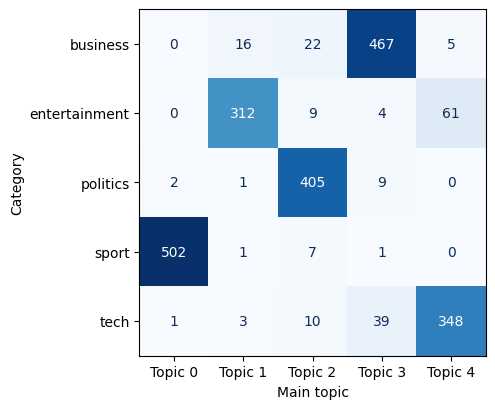

In [30]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.imshow(table.values, cmap="Blues")
for (i, j), n in np.ndenumerate(table.values):
    ax.text(j, i, n, ha="center", va="center", color="white" if n > 250 else "#0F2B58")
ax.set_xticks(range(5), [f"Topic {k}" for k in table.columns])
ax.set_yticks(range(5), table.index)
ax.set_xlabel("Main topic")
ax.set_ylabel("Category")
plt.show()

Purity adds the largest count of each column of the table:

$$\text{purity} = \frac{502 + 312 + 405 + 467 + 348}{2225} = \frac{2034}{2225} = 0.914$$

The largest mismatch in the table is the 61 entertainment articles with Topic 4, the technology topic, as their main topic.

The titles of the first 8 of these articles are displayed:

In [31]:
print(bbc.loc[[i for i in range(len(bbc)) if bbc.loc[i, "category"] == "entertainment" and main_topic[i] == 4], "title"].head(8).tolist())

['Fears raised over ballet future', 'Downloads enter US singles chart', "Pop band Busted to 'take a break'", "Streets have 'album of the year'", 'Manics in charge of BBC 6 Music', 'Band Aid retains number one spot', 'Elvis set to top UK singles chart', 'Wal-Mart is sued over rude lyrics']


Most of these articles are about music, the second top word of Topic 4.

For 2 pairs of top words of Topic 2, the articles that contain each word and the articles that contain both words are counted:

In [32]:
sets = [set(article) for article in articles]
for first, second in (("government", "labour"), ("party", "election")):
    print(first, sum(first in s for s in sets), "|", second, sum(second in s for s in sets), "| both", sum(first in s and second in s for s in sets))

government 480 | labour 235 | both 163
party 271 | election 229 | both 148


Most articles that contain `labour` also contain `government`, and most articles that contain `election` also contain `party`.

`CoherenceModel()` calculates the c_v score of each topic from its 10 top words. The c_v of the model is the average of the scores of its topics.

`processes=1` runs the calculation in a single process, which also lets it run on a Windows PC.

In [33]:
coherence = CoherenceModel(model=lda, texts=articles, dictionary=dictionary, coherence="c_v", topn=10, processes=1)
print("c_v of the model:", round(coherence.get_coherence(), 3))
print("c_v of each topic:", [round(float(c), 3) for c in coherence.get_coherence_per_topic()])

c_v of the model: 0.646
c_v of each topic: [0.704, 0.52, 0.789, 0.609, 0.608]


Topic 1 has the lowest score. Its top words include `us`, mostly the lowercased abbreviation `US`, and `include`, neither of which belongs to film and entertainment.

## Exercises

### Exercise 1: Scores by Entity Type

Calculate the **precision, recall, and F1 of spaCy for each entity type**: `PER`, `ORG`, `LOC`, and `MISC`. For each type, replace every tag of another type with `O` in both the gold and predicted sequences, then apply `evaluate()`.

Display:

- The precision, recall, and F1 of each type.

- A grouped bar chart with the entity types on the horizontal axis and separate bars for precision, recall, and F1.

In a Markdown cell, identify the type with the lowest F1 and explain the result with sentence `144` as an example.

In [34]:
# TODO: Calculate the precision, recall, and F1 of spaCy for each entity type and plot them as grouped bars.


**Expected results:**

- The F1 should be about **0.652** for `PER`, **0.401** for `ORG`, **0.776** for `LOC`, and **0.580** for `MISC`.

- `ORG` has the lowest F1. Sports clubs carry the names of their cities, such as `Liverpool` and `Sheffield Wednesday` in sentence `144`, which CoNLL-2003 tags as organizations and spaCy labels as places.

### Exercise 2: Types of Incorrect Predictions

Sort each **incorrect prediction of spaCy**, a predicted entity that matches no gold entity exactly, into one of these groups:

- **Wrong type:** the prediction has the same start and end as a gold entity but a different type.

- **Wrong boundaries:** the prediction overlaps at least one gold entity but has different boundaries, whatever its type.

- **No overlap:** the prediction shares no token with any gold entity.

Display:

- The number of incorrect predictions in each group.

- The first 3 predictions of each of the first two groups, with their `sentence_id` and the gold entities they overlap.

In a Markdown cell, explain what the first 2 predictions with wrong boundaries have in common and how the third differs.

In [35]:
# TODO: Sort the incorrect predictions of spaCy into wrong type, wrong boundaries, and no overlap, and display the number in each group and 3 examples of the first two.


**Expected results:**

- About **247** predictions have the wrong type, **230** the wrong boundaries, and **54** no overlap, out of about 531 incorrect predictions. Nearly half of the incorrect predictions therefore have the correct boundaries but the wrong type.

- The first predictions with the wrong type should include `Uzbekistan`, predicted as `MISC` instead of `LOC` in sentence `8`, and `Alessandro Troncon`, predicted as `ORG` instead of `PER` in sentence `33`.

- The first predictions with wrong boundaries should be `the Asian Games` in sentence `8`, `the World Cup` in sentence `50`, and `Inzamamul Haq st Germon` in sentence `101`, which overlaps 2 gold `PER` entities.

- The first 2 include the article `the` in the name of an event, which CoNLL-2003 leaves outside the entity. The third combines 2 names from a cricket scorecard into one entity.

### Exercise 3: Articles Where Each Topic Is Strongest

For each topic, display the titles of the **3 articles** with the highest proportion of that topic in their mixtures.

Display:

- The 3 titles of each topic, with the proportion of the topic in each article.

In a Markdown cell, state whether the name given to each topic fits the content of its articles.

In [36]:
# TODO: Display the titles of the 3 articles with the highest proportion of each topic.


**Expected results:**

- Each of the 15 articles should have a proportion above **0.99** of its topic.

- The titles should include `Nadal puts Spain 2-0 up` for Topic 0, `Critics back Aviator for Oscars` for Topic 1, `Kilroy launches 'Veritas' party` for Topic 2, `UK bank seals South Korean deal` for Topic 3, and `Apple laptop is 'greatest gadget'` for Topic 4.

- `Apple laptop is 'greatest gadget'` appears twice because the article occurs twice in the corpus.

- The titles fit the names given to the topics.

### Exercise 4 (Extension): Topics from Non-Negative Matrix Factorization

Join the lemmas of each article into one string, and convert the strings into TF-IDF weights with `TfidfVectorizer(vocabulary=...)`, using the words of `dictionary` as its vocabulary.

Train **scikit-learn**'s `NMF` on the TF-IDF weights with 5 topics, `init="nndsvd"`, and `max_iter=500`.

The `fit_transform()` method of `NMF` returns the topic weights of each article, and its `components_` attribute contains the word weights of each topic.

Display:

- The 6 top words of each NMF topic, the words with the highest weights.

- The purity of the main topics of NMF, where the main topic of an article is the topic with its highest weight.

- The c_v of the NMF topics, calculated with `CoherenceModel(topics=..., texts=articles, dictionary=dictionary, coherence="c_v", topn=10, processes=1)` on their 10 top words.

In a Markdown cell, compare the NMF and LDA topics in their themes, purity, and c_v.

In [37]:
# TODO: Train NMF with 5 topics on TF-IDF weights and display its top words, its purity, and its c_v.


**Expected results:**

- The 5 NMF topics should read as business, sport, politics, film and entertainment, and technology, the same themes as LDA.

- The purity should be about **0.929** and the c_v about **0.785**, both higher than those of LDA on this corpus.